# Credit Card Fraud Detection: Feature Engineering and Modeling

This notebook builds a model that predicts whether a card transaction is **fraud (1)** or **not fraud (0)**.

**Steps:**
1. Baseline model: KNN on the raw features
2. Data exploration and a new engineered feature
3. KNN experiments: feature scaling and the new feature
4. Feature selection: correlation and removing features
5. Comparing other models: Logistic Regression, Decision Tree and ensemble methods (Bagging, Random Forest, Gradient Boosting, AdaBoost)
6. Conclusion and limitations

**Dataset:** `card_transdata.csv`, 1,000,000 transactions, 7 features and the `fraud` target.

Reminder from the data exploration: the data is imbalanced (8.74% fraud), so a model that always predicts "not fraud" gets **91.26% accuracy**. That is the minimum a useful model has to beat, and **recall and precision matter more than accuracy**.

**Metrics used** (for the fraud class):
- **Accuracy:** share of all transactions classified correctly
- **Recall:** of all real fraud cases, how many did the model catch?
- **Precision:** of all transactions flagged as fraud, how many were really fraud?
- **F1 score:** one number that combines precision and recall (it is only high when both are high)

# Part 1: Baseline model

## 1. Load the data

In [1]:
# Import pandas for data loading
import pandas as pd

In [2]:
# Load the dataset and preview the first rows
df = pd.read_csv('card_transdata.csv')
df.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


## 2. Features (X) and target (y)

In [3]:
# Features: all columns except the target
# Target: the fraud label (1 = fraud, 0 = not fraud)
features = df.drop(columns="fraud")
target = df["fraud"]

## 3. Train-test split

80% of the data is used for training and 20% for testing. `stratify=target` keeps the fraud rate (8.74%) the same in the train and test sets, which is important because the data is imbalanced.

In [4]:
# Split into 80% train / 20% test, stratified on the target
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.20, random_state=10 ,stratify=target)

## 4. Baseline model: KNN (k = 3)

K-Nearest Neighbors classifies a transaction based on the 3 most similar transactions in the training set. Features are **not scaled yet**, so this is a first baseline.

In [5]:
# Import the KNN classifier
from sklearn.neighbors import KNeighborsClassifier

In [6]:
# Create the model with k = 3 neighbors
knn = KNeighborsClassifier(n_neighbors=3)

In [7]:
%%time
# Train the model and predict on the test set (timed)
knn.fit(X_train, y_train)
pred = knn.predict(X_test)

CPU times: total: 16.1 s
Wall time: 16.3 s


In [8]:
# Predictions on the test set (1 = fraud, 0 = not fraud)
pred = knn.predict(X_test)
pred

array([1., 0., 0., ..., 0., 0., 0.], shape=(200000,))

## 5. Evaluation

In [9]:
# Accuracy on the test set (knn.score returns accuracy for classifiers)
knn.score(X_test, y_test)

0.984925

In [10]:
# Accuracy: share of all transactions classified correctly
from sklearn.metrics import accuracy_score
accuracy_score(y_test,pred)

0.984925

In [11]:
# Recall: of all real fraud cases, how many did the model catch?
from sklearn.metrics import recall_score
recall_score(y_test,pred)

0.92992391739603

In [12]:
# Precision: of all transactions flagged as fraud, how many were really fraud?
from sklearn.metrics import precision_score
precision_score(y_test,pred)

0.9008090435553585

## Results: baseline KNN (k = 3, unscaled features)

| Metric | Score | Meaning |
|---|---|---|
| Accuracy | **98.49%** | vs. 91.26% for "always predict not fraud", so the model learned real patterns |
| Recall | **92.99%** | catches about 93 of every 100 real fraud cases |
| Precision | **90.08%** | about 9 of every 10 fraud alerts are real fraud |

Training and predicting on 800,000 / 200,000 rows took about **11 seconds**.

**In numbers** (test set: 200,000 transactions, 17,481 of them fraud). These counts are derived from the scores above; a confusion matrix will confirm them:

| | Predicted not fraud | Predicted fraud |
|---|---|---|
| **Actual not fraud** | 180,729 (correct) | **1,790 false alarms** |
| **Actual fraud** | **1,225 missed fraud** | 16,256 caught |

## Key takeaways

- The baseline model is clearly better than guessing, with **high recall and precision** for a first model.
- It still **misses about 1,225 fraud cases** (false negatives) and **wrongly flags about 1,790 legitimate transactions** (false positives). In a real bank, missed fraud costs money, while false alarms block real customers.
- Because KNN is distance-based and the continuous features are not scaled, the very large values in `distance_from_home` and `distance_from_last_transaction` likely **dominate the distances**. Scaling may improve the results.

## Next steps

- Explore the features to find fraud patterns and engineer a new feature (Part 2).
- Test **feature scaling** and the new feature with KNN (Part 3).
- Compare with other models, including **ensemble models** (Part 5).

# Part 2: Data exploration and feature engineering

## 6. Convert the binary columns

The 0/1 columns are stored as floats (`1.0`, `0.0`). They are converted to integers so they are easier to read and group.

In [13]:
binary_cols = ["repeat_retailer", "used_chip", "used_pin_number", "online_order", "fraud"]
df[binary_cols] = df[binary_cols].astype(int)

df.dtypes

distance_from_home                float64
distance_from_last_transaction    float64
ratio_to_median_purchase_price    float64
repeat_retailer                     int64
used_chip                           int64
used_pin_number                     int64
online_order                        int64
fraud                               int64
dtype: object

In [14]:
df.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1,1,0,0,0
1,10.829943,0.175592,1.294219,1,0,0,0,0
2,5.091079,0.805153,0.427715,1,0,0,1,0
3,2.247564,5.600044,0.362663,1,1,0,1,0
4,44.190936,0.566486,2.222767,1,1,0,1,0


## 7. Fraud patterns in the binary features

Share of transactions with each binary feature, for non-fraud (0) and fraud (1).

In [15]:
df.groupby("fraud")[["repeat_retailer", "used_chip", "used_pin_number", "online_order"]].mean()

,repeat_retailer,used_chip,used_pin_number,online_order
fraud,,,,
0,0.881672,0.359402,0.109944,0.622225
1,0.880119,0.256399,0.003123,0.946318


### Fraud patterns in the binary features

The table shows the share of transactions with each feature, separately for non-fraud (0) and fraud (1) transactions.

| Feature | Not fraud | Fraud |
|---|---|---|
| online_order | 62.2% | 94.6% |
| used_pin_number | 11.0% | 0.3% |
| used_chip | 35.9% | 25.6% |
| repeat_retailer | 88.2% | 88.0% |

**Key insights:**
1. **Almost all fraud happens online:** 94.6% of fraudulent transactions are online orders, compared to 62.2% of normal transactions. This matches the typical "card not present" fraud pattern, where a stolen card number is used without the physical card.
2. **A PIN almost always prevents fraud:** only 0.3% of fraudulent transactions used a PIN, compared to 11.0% of normal ones. A fraudster usually doesn't know the PIN.
3. **Chip use is lower in fraud:** 25.6% vs. 35.9%, which also points to transactions without the physical card.
4. **Repeat retailer shows no difference:** 88.0% vs. 88.2%, so this feature is probably not useful for detecting fraud. It is a candidate to drop during feature selection.

**Feature engineering idea:** the two strongest signals (online order and no PIN) are combined into one new feature below.

In [47]:
# Chart style for this notebook: calm, consistent colors and no top/right border
import matplotlib.pyplot as plt

BLUE = "#2a78d6"         # main color: the high-fraud group / the result we focus on
LIGHT_BLUE = "#9ec5f4"   # context color: the comparison group
GRID = "#e1e0d9"         # light gridlines
METRIC_COLORS = {"Precision": "#2a78d6", "Recall": "#eb6834", "F1": "#1baf7a"}   # same color per metric in every chart

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})

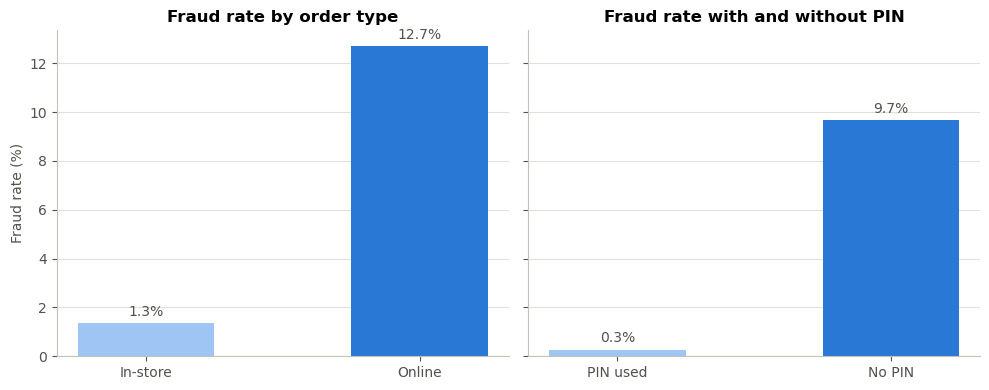

In [48]:
# Fraud rate for online vs. in-store orders, and with vs. without PIN
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

online_rate = df.groupby("online_order")["fraud"].mean() * 100      # index 0 = in-store, 1 = online
pin_rate = df.groupby("used_pin_number")["fraud"].mean() * 100       # index 0 = no PIN, 1 = PIN used

# Low-fraud group first (light blue), high-fraud group second (blue)
panels = [
    (axes[0], ["In-store", "Online"], [online_rate[0], online_rate[1]], "Fraud rate by order type"),
    (axes[1], ["PIN used", "No PIN"], [pin_rate[1], pin_rate[0]], "Fraud rate with and without PIN"),
]
for ax, labels, values, title in panels:
    bars = ax.bar(labels, values, color=[LIGHT_BLUE, BLUE], width=0.5)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, color="#52514e")    # value on top of each bar
    ax.set_title(title)
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Fraud rate (%)")
plt.tight_layout()
plt.savefig("eda_fraud_rate.png", dpi=150)   # saved for the slides
plt.show()

## 8. New feature: online order without PIN

In [16]:
# Create a new feature: 1 if the transaction is an online order WITHOUT a PIN, otherwise 0
# (combines the two strongest fraud signals found above)
df["online_no_pin"] = ((df["online_order"] == 1) & (df["used_pin_number"] == 0)).astype(int)

# Fraud rate for transactions with (1) and without (0) this pattern
df.groupby("online_no_pin")["fraud"].mean()

online_no_pin
0    0.011966
1    0.140887
Name: fraud, dtype: float64

In [17]:
df

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud,online_no_pin
0,57.877857,0.311140,1.945940,1,1,0,0,0,0
1,10.829943,0.175592,1.294219,1,0,0,0,0,0
2,5.091079,0.805153,0.427715,1,0,0,1,0,1
3,2.247564,5.600044,0.362663,1,1,0,1,0,1
4,44.190936,0.566486,2.222767,1,1,0,1,0,1
...,...,...,...,...,...,...,...,...,...
999995,2.207101,0.112651,1.626798,1,1,0,0,0,0
999996,19.872726,2.683904,2.778303,1,1,0,0,0,0
999997,2.914857,1.472687,0.218075,1,1,0,1,0,1
999998,4.258729,0.242023,0.475822,1,0,0,1,0,1


### New feature: online order without PIN

| online_no_pin | Fraud rate |
|---|---|
| 0 | 1.2% |
| 1 | 14.1% |

Online orders without a PIN have a fraud rate of 14.1%, about 12 times higher than all other transactions (1.2%). For comparison, online orders alone have a fraud rate of about 12.7% vs. 1.3% for in-store orders (about 9.5 times higher), derived from the table above. So combining the two signals makes the pattern slightly stronger. Whether this new feature actually improves the model will be tested in the modeling notebook by comparing recall and precision.

## 9. Continuous features: fraud vs. non-fraud

In [18]:
# Compare the typical (median) values of the continuous features for non-fraud (0) vs. fraud (1)
df.groupby("fraud")[["distance_from_home", "distance_from_last_transaction", "ratio_to_median_purchase_price"]].median()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price
fraud,,,
0,9.673847,0.985074,0.913950
1,15.454219,1.157631,5.071294


### Continuous features: fraud vs. non-fraud (median)

| Feature | Not fraud | Fraud |
|---|---|---|
| ratio_to_median_purchase_price | 0.91 | 5.07 |
| distance_from_home | 9.7 | 15.5 |
| distance_from_last_transaction | 0.99 | 1.16 |

Medians are used because these features are strongly right-skewed with extreme outliers.

- **Purchase price is the strongest signal:** a typical fraudulent purchase is about 5 times the customer's usual (median) purchase price, while normal purchases are close to it (0.91).
- **Fraud happens further from home:** the median distance from home is about 1.6 times higher for fraud.
- **Distance from the last transaction** shows only a small difference in the median, but its extreme values may still carry signal, so the feature is kept.

# Part 3: KNN experiments

The same KNN model (k = 3) is trained with different feature sets and scalers to see what improves it. All experiments use the **same stratified split** (`random_state=10`), so the results are comparable.

| Model | Features | Scaling |
|---|---|---|
| A | 7 original features | none (same as the baseline) |
| B | 7 original features | StandardScaler |
| C | 7 original + `online_no_pin` | StandardScaler |
| B2 | 7 original features | MinMaxScaler |

## 10. New train-test split (includes `online_no_pin`)

In [19]:
from sklearn.model_selection import train_test_split

# Features: all columns except the target (includes the new online_no_pin feature)
X = df.drop(columns="fraud")
y = df["fraud"]

# 80/20 split, stratified so both sets keep the 8.74% fraud rate
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=10, stratify=y
)

X_train.columns

Index(['distance_from_home', 'distance_from_last_transaction',
       'ratio_to_median_purchase_price', 'repeat_retailer', 'used_chip',
       'used_pin_number', 'online_order', 'online_no_pin'],
      dtype='object')

## 11. Model A: baseline KNN, no scaling

This repeats the baseline from Part 1 as a check: the results are the same.

In [20]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

# The 7 original features (without the new online_no_pin)
original_cols = ["distance_from_home", "distance_from_last_transaction",
                 "ratio_to_median_purchase_price", "repeat_retailer",
                 "used_chip", "used_pin_number", "online_order"]

# Model A: baseline KNN on the original features, no scaling (same as Day 1)
knn_a = KNeighborsClassifier(n_neighbors=3)
knn_a.fit(X_train[original_cols], y_train)
pred_a = knn_a.predict(X_test[original_cols])

print("A - Accuracy:", accuracy_score(y_test, pred_a))
print("A - Precision:", precision_score(y_test, pred_a))
print("A - Recall:", recall_score(y_test, pred_a))

A - Accuracy: 0.984925
A - Precision: 0.9008090435553585
A - Recall: 0.92992391739603


## 12. Model B: StandardScaler

In [21]:
from sklearn.preprocessing import StandardScaler

# Model B: same 7 features, but scaled
scaler_b = StandardScaler()
scaler_b.fit(X_train[original_cols])                       # learn mean/std from TRAIN only
X_train_b = scaler_b.transform(X_train[original_cols])
X_test_b = scaler_b.transform(X_test[original_cols])

knn_b = KNeighborsClassifier(n_neighbors=3)
knn_b.fit(X_train_b, y_train)
pred_b = knn_b.predict(X_test_b)

print("B - Accuracy:", accuracy_score(y_test, pred_b))
print("B - Precision:", precision_score(y_test, pred_b))
print("B - Recall:", recall_score(y_test, pred_b))

B - Accuracy: 0.998935
B - Precision: 0.9963780614004829
B - Recall: 0.9914192551913507


## 13. Model C: StandardScaler + the new `online_no_pin` feature

In [22]:
# Model C: the 7 original features + the new online_no_pin feature, scaled
c_cols = original_cols + ["online_no_pin"]

scaler_c = StandardScaler()
scaler_c.fit(X_train[c_cols])                              # learn mean/std from TRAIN only
X_train_c = scaler_c.transform(X_train[c_cols])
X_test_c = scaler_c.transform(X_test[c_cols])

knn_c = KNeighborsClassifier(n_neighbors=3)
knn_c.fit(X_train_c, y_train)
pred_c = knn_c.predict(X_test_c)

print("C - Accuracy:", accuracy_score(y_test, pred_c))
print("C - Precision:", precision_score(y_test, pred_c))
print("C - Recall:", recall_score(y_test, pred_c))

C - Accuracy: 0.99894
C - Precision: 0.9965495428144229
C - Recall: 0.9913048452605686


## 14. Model B2: MinMaxScaler

In [23]:
from sklearn.preprocessing import MinMaxScaler

# Model B2: same as B (7 original features), but with MinMaxScaler instead of StandardScaler
scaler_b2 = MinMaxScaler()
scaler_b2.fit(X_train[original_cols])                      # learn min/max from TRAIN only
X_train_b2 = scaler_b2.transform(X_train[original_cols])
X_test_b2 = scaler_b2.transform(X_test[original_cols])

knn_b2 = KNeighborsClassifier(n_neighbors=3)
knn_b2.fit(X_train_b2, y_train)
pred_b2 = knn_b2.predict(X_test_b2)

print("B2 - Accuracy:", accuracy_score(y_test, pred_b2))
print("B2 - Precision:", precision_score(y_test, pred_b2))
print("B2 - Recall:", recall_score(y_test, pred_b2))

B2 - Accuracy: 0.999125
B2 - Precision: 0.9965568690462527
B2 - Recall: 0.9934214289800355


## Results: KNN experiments

| Model | Accuracy | Precision | Recall |
|---|---|---|---|
| A: no scaling | 98.49% | 90.08% | 92.99% |
| B: StandardScaler | 99.89% | 99.64% | 99.14% |
| C: StandardScaler + `online_no_pin` | 99.89% | 99.65% | 99.13% |
| B2: MinMaxScaler | **99.91%** | **99.66%** | **99.34%** |

**Key takeaways:**
- **Scaling is the biggest improvement.** Recall goes from about 93% to about 99%. Without scaling, the large distance values dominate the KNN distances.
- **The new `online_no_pin` feature does not help** (C vs. B: almost the same). KNN can already find this pattern from `online_order` and `used_pin_number`.
- **MinMaxScaler (B2) gives the best results**, so this setup is used for the model comparison in Part 5.

# Part 4: Feature selection

## 15. Correlation with the target

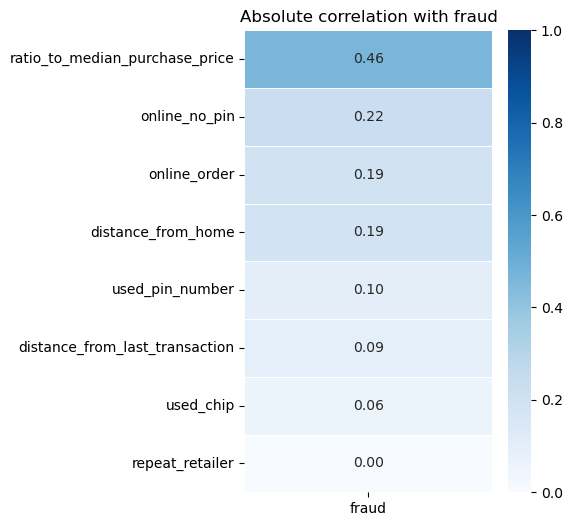

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Correlation of every column with the target (fraud)
fraud_corr = df.corr()[["fraud"]]          # double brackets -> keeps it as a table (DataFrame) for the heatmap

# 2. Remove fraud itself (correlation with itself is always 1)
fraud_corr = fraud_corr.drop("fraud")

# 3. Absolute values (strength of the relationship), strongest first
fraud_corr = fraud_corr.abs().sort_values(by="fraud", ascending=False)

# 4. Heatmap: one column (fraud), one row per feature
plt.figure(figsize=(4, 6))
sns.heatmap(fraud_corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=.5)
plt.title("Absolute correlation with fraud")
plt.show()

## 16. Correlation between all features

**Note:** this cell reloads the data, so from here on `df` has the 7 original features again (without `online_no_pin`).

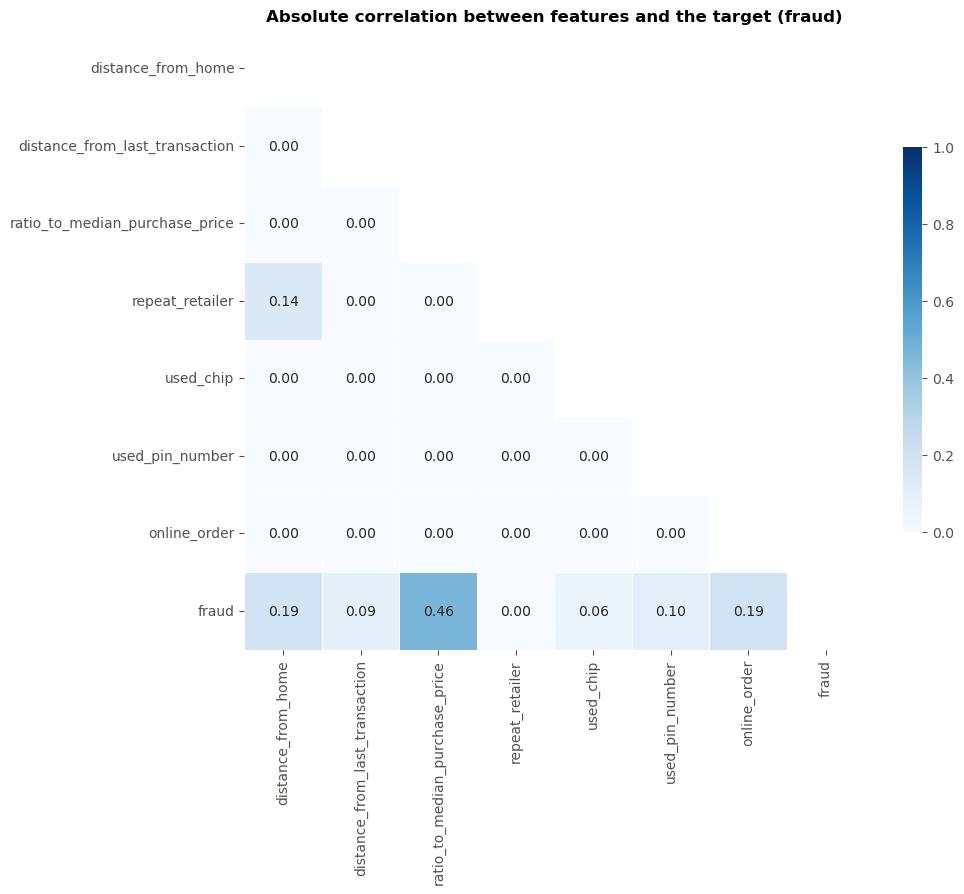

In [49]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load the data
df = pd.read_csv("card_transdata.csv")

# 2. Convert the 0/1 columns (including the target) to integers
binary_cols = ["repeat_retailer", "used_chip", "used_pin_number", "online_order", "fraud"]
df[binary_cols] = df[binary_cols].astype(int)

# 3. Correlation of ALL columns with each other (fraud included as the target)
corr = np.abs(df.corr())

# 4. Mask the upper triangle (it is a mirror of the lower one)
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True

# 5. Heatmap
f, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(corr, mask=mask, vmin=0, vmax=1, cmap="Blues", square=True, linewidths=.5,
            cbar_kws={"shrink": .5}, annot=True, fmt=".2f")
plt.title("Absolute correlation between features and the target (fraud)")
plt.show()

## 17. Testing feature removal

`repeat_retailer` showed almost no difference between fraud and non-fraud (Part 2). Two models test whether removing weak features helps (both with StandardScaler, to compare with Model B):

- **Model D:** without `repeat_retailer`
- **Model E:** without `repeat_retailer` and `used_chip`

In [26]:
# Model D: drop the target and repeat_retailer from the features
X = df.drop(columns=["fraud", "repeat_retailer"])
y = df["fraud"]

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=10, stratify=y)

# Scale: fit on train only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# KNN with k = 3
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)
pred = knn.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))

Accuracy: 0.99786
Precision: 0.9915259122614861
Recall: 0.9839254047251301


In [27]:
# Model E: drop the target, repeat_retailer and used_chip from the features
X = df.drop(columns=["fraud", "repeat_retailer", "used_chip"])
y = df["fraud"]

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=10, stratify=y)

# Scale: fit on train only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# KNN with k = 3
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)
pred = knn.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))

Accuracy: 0.983175
Precision: 0.8939495423085511
Recall: 0.916194725702191


## Results: feature removal

| Model | Accuracy | Precision | Recall |
|---|---|---|---|
| B: all 7 features | **99.89%** | **99.64%** | **99.14%** |
| D: without `repeat_retailer` | 99.79% | 99.15% | 98.39% |
| E: without `repeat_retailer` and `used_chip` | 98.32% | 89.39% | 91.62% |

**Key takeaways:**
- Removing features made the model **worse**, especially removing `used_chip` (recall drops to 91.62%).
- Even though `repeat_retailer` shows almost no difference on its own, keeping all 7 features gives the best results.
- **Decision:** keep all 7 original features.

# Part 5: Comparing models

All models use the **best setup from the KNN experiments (B2)**: the 7 original features, the same stratified split (`random_state=10`) and MinMaxScaler. This makes the comparison fair.

## 18. Setup: features, split and scaling

In [28]:
# Same setup as Model B2: 7 original features, same split, MinMaxScaler (fit on train only)
from sklearn.metrics import classification_report

X = df[original_cols]
y = df["fraud"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=10, stratify=y)

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 19. Logistic Regression

A simple linear model and a common baseline for classification. It predicts the probability of fraud and uses 0.5 as the threshold.

In [29]:
# Logistic Regression: train on the train set, predict on the test set, show the report
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
pred = log_reg.predict(X_test_scaled)
print(classification_report(y_test, pred, digits=3))

              precision    recall  f1-score   support

           0      0.947     0.996     0.971    182519
           1      0.906     0.420     0.574     17481

    accuracy                          0.945    200000
   macro avg      0.927     0.708     0.772    200000
weighted avg      0.944     0.945     0.936    200000



**Result:** accuracy 94.5%, but recall for fraud is only **42.0%**: the model misses more than half of the fraud cases. Precision is 90.6%. A linear model cannot capture the combined rules (e.g. "online AND no PIN AND high price") that separate fraud in this data.

## 20. Decision Tree

A tree learns "if ... then ..." rules from the features. `max_depth=10` limits it to 10 levels of splits.

In [30]:
# Decision Tree with max_depth=10
from sklearn.tree import DecisionTreeClassifier

tree_clf = DecisionTreeClassifier(max_depth=10, random_state=42)
tree_clf.fit(X_train_scaled, y_train)
pred = tree_clf.predict(X_test_scaled)
print(classification_report(y_test, pred, digits=3))

              precision    recall  f1-score   support

           0      1.000     1.000     1.000    182519
           1      1.000     1.000     1.000     17481

    accuracy                          1.000    200000
   macro avg      1.000     1.000     1.000    200000
weighted avg      1.000     1.000     1.000    200000



**Result:** all scores are 1.000 (rounded to 3 decimals), which means almost no errors on 200,000 test transactions.

A near-perfect score always needs a check. There is **no data leakage**: `fraud` is not in the features, and the scaler was fit on the train set only. The next cell shows the rules a small tree (only 3 levels) learns, to understand why the scores are so high.

In [31]:
# A small tree (max_depth=3) to show the rules it learns
from sklearn.tree import export_text

small_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
small_tree.fit(X_train, y_train)          # unscaled, so the thresholds are readable
print(export_text(small_tree, feature_names=original_cols))

|--- ratio_to_median_purchase_price <= 4.00
|   |--- distance_from_home <= 100.00
|   |   |--- distance_from_last_transaction <= 50.03
|   |   |   |--- class: 0
|   |   |--- distance_from_last_transaction >  50.03
|   |   |   |--- class: 0
|   |--- distance_from_home >  100.00
|   |   |--- online_order <= 0.50
|   |   |   |--- class: 0
|   |   |--- online_order >  0.50
|   |   |   |--- class: 1
|--- ratio_to_median_purchase_price >  4.00
|   |--- online_order <= 0.50
|   |   |--- distance_from_home <= 100.00
|   |   |   |--- class: 0
|   |   |--- distance_from_home >  100.00
|   |   |   |--- class: 1
|   |--- online_order >  0.50
|   |   |--- used_pin_number <= 0.50
|   |   |   |--- class: 1
|   |   |--- used_pin_number >  0.50
|   |   |   |--- class: 0



**What the rules show:**
- Fraud is predicted when the purchase price is more than **4 times** the customer's usual price, the order is **online** and **no PIN** was used.
- Fraud is also predicted when the transaction is more than **100** away from home and is **online**.
- The thresholds are **round numbers** (4.00, 100.00), and only 3 levels of rules already separate most of the fraud.

This suggests the dataset is **synthetic** and the fraud labels were generated with simple rules. Tree-based models can learn these rules almost exactly, which explains the near-perfect scores. On real fraud data, the scores would be much lower.

## 21. Bagging

Bagging trains 100 decision trees in parallel, each on a random sample of the training data. The final prediction is a majority vote.

In [32]:
# Bagging: 100 decision trees (max_depth=10), each trained on a random sample
from sklearn.ensemble import BaggingClassifier

bagging_clf = BaggingClassifier(DecisionTreeClassifier(max_depth=10),
                                n_estimators=100, n_jobs=-1, random_state=42)
bagging_clf.fit(X_train_scaled, y_train)
pred = bagging_clf.predict(X_test_scaled)
print(classification_report(y_test, pred, digits=3))

              precision    recall  f1-score   support

           0      1.000     1.000     1.000    182519
           1      1.000     1.000     1.000     17481

    accuracy                          1.000    200000
   macro avg      1.000     1.000     1.000    200000
weighted avg      1.000     1.000     1.000    200000



## 22. Random Forest

Like Bagging, but each tree also uses a random subset of the features at each split, so the trees are more different from each other.

In [33]:
# Random Forest: 100 trees with max_depth=10
from sklearn.ensemble import RandomForestClassifier

randomforest_clf = RandomForestClassifier(n_estimators=100, max_depth=10,
                                          n_jobs=-1, random_state=42)
randomforest_clf.fit(X_train_scaled, y_train)
pred = randomforest_clf.predict(X_test_scaled)
print(classification_report(y_test, pred, digits=3))

              precision    recall  f1-score   support

           0      1.000     1.000     1.000    182519
           1      1.000     1.000     1.000     17481

    accuracy                          1.000    200000
   macro avg      1.000     1.000     1.000    200000
weighted avg      1.000     1.000     1.000    200000



## 23. Gradient Boosting

Trees are trained one after another: each new tree tries to correct the errors of the previous ones. Boosting usually works best with short trees (`max_depth=3`).

In [34]:
# Gradient Boosting: 100 short trees (max_depth=3), trained one after another
from sklearn.ensemble import GradientBoostingClassifier

gradient_clf = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
gradient_clf.fit(X_train_scaled, y_train)
pred = gradient_clf.predict(X_test_scaled)
print(classification_report(y_test, pred, digits=3))

              precision    recall  f1-score   support

           0      1.000     1.000     1.000    182519
           1      1.000     0.997     0.999     17481

    accuracy                          1.000    200000
   macro avg      1.000     0.999     0.999    200000
weighted avg      1.000     1.000     1.000    200000



## 24. AdaBoost

Also trained one after another, but each new model gives more weight to the transactions the previous models got wrong. By default it uses very short trees (one split each).

In [35]:
# AdaBoost: 100 very short trees (default)
from sklearn.ensemble import AdaBoostClassifier

adaboost_clf = AdaBoostClassifier(n_estimators=100, random_state=42)
adaboost_clf.fit(X_train_scaled, y_train)
pred = adaboost_clf.predict(X_test_scaled)
print(classification_report(y_test, pred, digits=3))

              precision    recall  f1-score   support

           0      1.000     1.000     1.000    182519
           1      0.998     0.999     0.999     17481

    accuracy                          1.000    200000
   macro avg      0.999     1.000     0.999    200000
weighted avg      1.000     1.000     1.000    200000



## 25. Model comparison

All models were tested on the same 200,000 test transactions (17,481 of them fraud). The scores are for the fraud class (1).

                     Accuracy  Precision  Recall      F1
Model                                                   
KNN (B2)               0.9991     0.9966  0.9934  0.9950
Logistic Regression    0.9455     0.9063  0.4195  0.5736
Decision Tree          1.0000     0.9999  1.0000  0.9999
Bagging                1.0000     0.9999  1.0000  1.0000
Random Forest          1.0000     1.0000  1.0000  1.0000
Gradient Boosting      0.9997     1.0000  0.9971  0.9985
AdaBoost               0.9998     0.9981  0.9993  0.9987


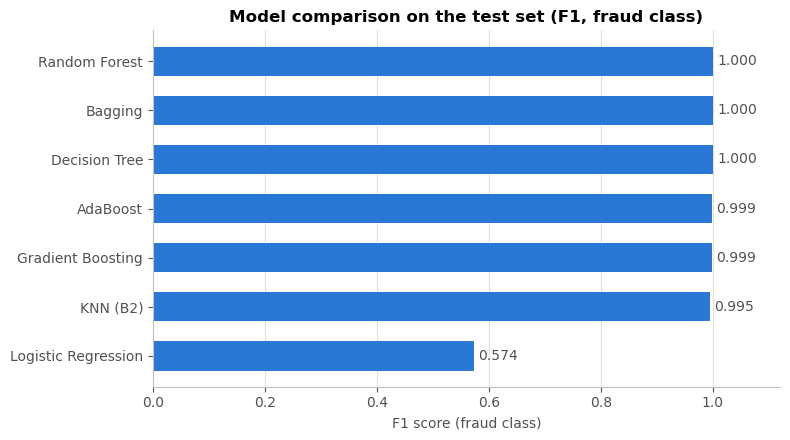

In [50]:
# Compare all models on the same test set (no retraining: uses the models trained above)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predictions of every model on the test set
# (KNN B2 uses pred_b2 from section 14: same rows, same features, same MinMaxScaler)
all_preds = {
    "KNN (B2)": pred_b2,
    "Logistic Regression": log_reg.predict(X_test_scaled),
    "Decision Tree": tree_clf.predict(X_test_scaled),
    "Bagging": bagging_clf.predict(X_test_scaled),
    "Random Forest": randomforest_clf.predict(X_test_scaled),
    "Gradient Boosting": gradient_clf.predict(X_test_scaled),
    "AdaBoost": adaboost_clf.predict(X_test_scaled),
}

# One row per model, scores for the fraud class (1)
results = []
for name, model_pred in all_preds.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, model_pred),
        "Precision": precision_score(y_test, model_pred),
        "Recall": recall_score(y_test, model_pred),
        "F1": f1_score(y_test, model_pred),
    })

results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(4))

# Chart: F1 score per model (one number that combines precision and recall), best model on top
f1_sorted = results_df["F1"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(f1_sorted.index, f1_sorted.values, color=BLUE, height=0.6)
ax.bar_label(bars, fmt="%.3f", padding=3, color="#52514e")    # value at the end of each bar
ax.set_xlim(0, 1.12)
ax.set_xlabel("F1 score (fraud class)")
ax.set_title("Model comparison on the test set (F1, fraud class)")
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)   # saved for the slides
plt.show()

**Result:**

| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Random Forest | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| Bagging | 1.0000 | 0.9999 | 1.0000 | 1.0000 |
| Decision Tree | 1.0000 | 0.9999 | 1.0000 | 0.9999 |
| AdaBoost | 0.9998 | 0.9981 | 0.9993 | 0.9987 |
| Gradient Boosting | 0.9997 | 1.0000 | 0.9971 | 0.9985 |
| KNN (B2) | 0.9991 | 0.9966 | 0.9934 | 0.9950 |
| Logistic Regression | 0.9455 | 0.9063 | 0.4195 | 0.5736 |

- **All tree-based models are near-perfect** (F1 ≥ 0.998). The differences between them are only a few transactions out of 200,000.
- **KNN with scaling is also very strong** (F1 0.995).
- **Logistic Regression is clearly the weakest:** it catches only 42% of fraud cases, because it can only draw a straight (linear) boundary and cannot learn combined rules such as "online AND no PIN AND high price".

## 26. Best model: confusion matrix

The Decision Tree is chosen as the best model: it reaches the same near-perfect scores as the ensembles, but it is faster and easier to explain. The confusion matrix shows the exact number of caught fraud cases, missed fraud cases and false alarms.

Fraud caught (true positives): 17481
Fraud missed (false negatives): 0
False alarms (false positives): 2
Normal transactions correct (true negatives): 182517


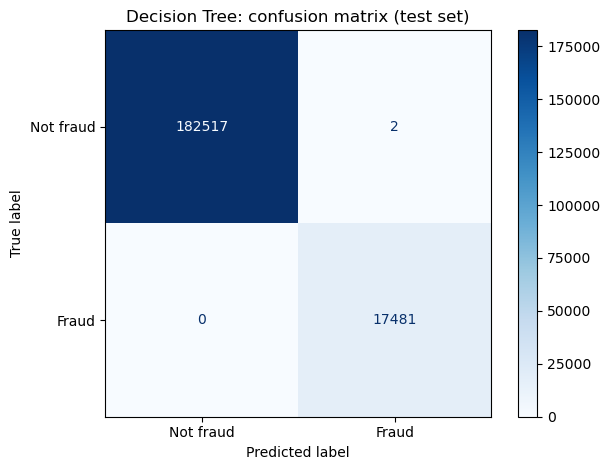

In [37]:
# Confusion matrix for the best model: Decision Tree
# (simplest of the near-perfect models: fast and easy to explain)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

tree_pred = tree_clf.predict(X_test_scaled)

# The 4 counts: true negatives, false positives, false negatives, true positives
tn, fp, fn, tp = confusion_matrix(y_test, tree_pred).ravel()
print("Fraud caught (true positives):", tp)
print("Fraud missed (false negatives):", fn)
print("False alarms (false positives):", fp)
print("Normal transactions correct (true negatives):", tn)

# Chart for the slides
ConfusionMatrixDisplay.from_predictions(y_test, tree_pred,
                                        display_labels=["Not fraud", "Fraud"],
                                        values_format="d",      # whole numbers, not 1.8e+05
                                        cmap="Blues")
plt.title("Decision Tree: confusion matrix (test set)")
plt.tight_layout()
plt.savefig("confusion_matrix_tree.png", dpi=150)   # saved for the slides
plt.show()

**Result:** the Decision Tree caught **all 17,481 fraud cases (0 missed)** and raised only **2 false alarms** out of 182,519 normal transactions. Random Forest and Bagging reach the same level, but the single tree is faster and its rules can be read and explained (see section 20).

## 27. Feature importance

Which features does the model rely on most? The Random Forest measures how much each feature helps to separate fraud from non-fraud.

ratio_to_median_purchase_price    0.5379
online_order                      0.1611
distance_from_home                0.1358
used_pin_number                   0.0580
used_chip                         0.0560
distance_from_last_transaction    0.0438
repeat_retailer                   0.0074
dtype: float64


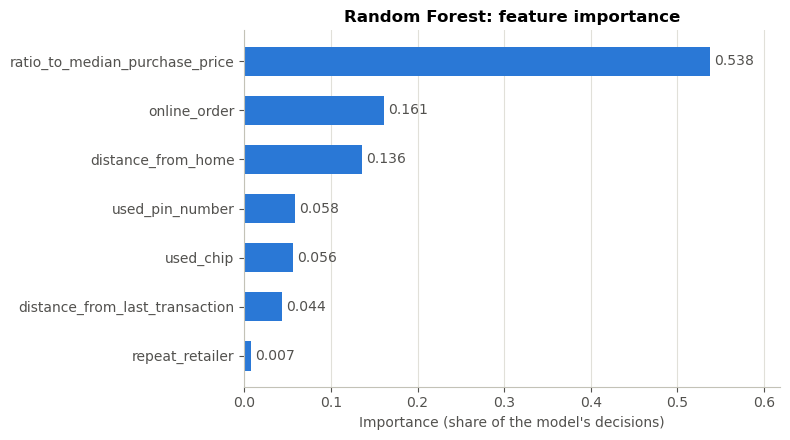

In [51]:
# Feature importance from the Random Forest: how much each feature helps the model
importance = pd.Series(randomforest_clf.feature_importances_, index=original_cols)
importance = importance.sort_values(ascending=False)
print(importance.round(4))

# Bar chart for the slides (most important feature on top)
fig, ax = plt.subplots(figsize=(8, 4.5))
imp_sorted = importance.sort_values()
bars = ax.barh(imp_sorted.index, imp_sorted.values, color=BLUE, height=0.6)
ax.bar_label(bars, fmt="%.3f", padding=3, color="#52514e")
ax.set_xlim(0, imp_sorted.max() * 1.15)
ax.set_xlabel("Importance (share of the model's decisions)")
ax.set_title("Random Forest: feature importance")
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)   # saved for the slides
plt.show()

**Result:**
- `ratio_to_median_purchase_price` is by far the most important feature (0.54): fraud is mostly about unusually large purchases.
- `online_order` (0.16) and `distance_from_home` (0.14) follow.
- `repeat_retailer` is almost unused (0.007). This matches the data exploration, where it showed no difference between fraud and non-fraud (88.0% vs. 88.2%).

**Importance is not the same as correlation:** correlation (section 15) looks at each feature alone and only at straight-line relationships. Feature importance shows what the model actually uses, including thresholds (e.g. distance from home > 100) and combinations of features. The top feature is the same in both, but the order of the weaker features changes.

## 28. Can the model work with fewer features?

Collecting and storing data costs money. Here the Decision Tree is trained with only the top 1, 2, ..., 7 most important features, to see how many features are really needed.

                    Precision  Recall      F1
Number of features                           
1                      0.6312  0.7467  0.6841
2                      0.9032  0.6965  0.7865
3                      0.8054  0.9331  0.8646
4                      0.8884  0.9336  0.9105
5                      0.9991  0.9339  0.9654
6                      0.9999  1.0000  1.0000
7                      0.9999  1.0000  0.9999


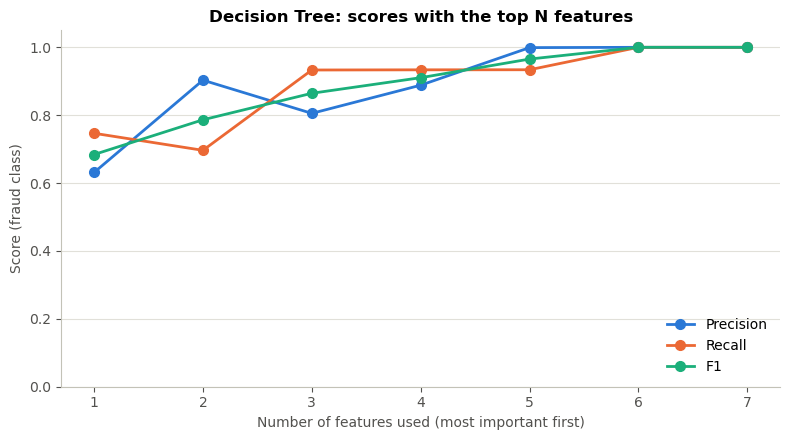

In [52]:
# Can a Decision Tree work with fewer features? (fewer features = less data to collect)
# Train the tree with the top 1, 2, ..., 7 most important features and compare the scores
X_train_df = pd.DataFrame(X_train_scaled, columns=original_cols)   # scaled data with column names
X_test_df = pd.DataFrame(X_test_scaled, columns=original_cols)

ranked_features = list(importance.index)   # features sorted by importance (from the cell above)

fewer_results = []
for n in range(1, len(ranked_features) + 1):
    cols = ranked_features[:n]                          # the top n features
    small_tree = DecisionTreeClassifier(max_depth=10, random_state=42)
    small_tree.fit(X_train_df[cols], y_train)
    small_pred = small_tree.predict(X_test_df[cols])
    fewer_results.append({
        "Number of features": n,
        "Features": ", ".join(cols),
        "Precision": precision_score(y_test, small_pred),
        "Recall": recall_score(y_test, small_pred),
        "F1": f1_score(y_test, small_pred),
    })

fewer_df = pd.DataFrame(fewer_results).set_index("Number of features")
print(fewer_df[["Precision", "Recall", "F1"]].round(4))

# Line chart: how the scores change when features are added (same metric colors as the other charts)
fig, ax = plt.subplots(figsize=(8, 4.5))
for metric, color in METRIC_COLORS.items():
    ax.plot(fewer_df.index, fewer_df[metric], marker="o", markersize=7, linewidth=2, color=color, label=metric)
ax.set_xticks(fewer_df.index)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Number of features used (most important first)")
ax.set_ylabel("Score (fraud class)")
ax.set_title("Decision Tree: scores with the top N features")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("fewer_features.png", dpi=150)   # saved for the slides
plt.show()

**Result:** the features are added in order of importance (`ratio_to_median_purchase_price`, `online_order`, `distance_from_home`, `used_pin_number`, `used_chip`, `distance_from_last_transaction`, `repeat_retailer`).

| Features used | Precision | Recall | F1 |
|---|---|---|---|
| Top 5 | 0.9991 | 0.9339 | 0.9654 |
| Top 6 (+ `distance_from_last_transaction`) | 0.9999 | 1.0000 | 1.0000 |
| All 7 (+ `repeat_retailer`) | 0.9999 | 1.0000 | 0.9999 |

- **6 features are enough:** `repeat_retailer` can be dropped without losing any performance, so this data would not need to be collected for the model (a possible cost saving).
- **`distance_from_last_transaction` is needed:** without it, recall drops from 1.000 to 0.934 (about 6.6% of fraud cases missed). Its median barely differed between fraud and non-fraud (section 9), but its extreme values carry the signal, as suspected in the data exploration.
- **The answer depends on the model:** with KNN, removing `repeat_retailer` made the results slightly worse (Model D, section 17), while the Decision Tree does not need it at all.

## 29. Handling the imbalance: oversampling and undersampling

Only 8.74% of the transactions are fraud. Logistic Regression caught only 42% of fraud cases, so here it is retrained on balanced training data (same methods as in class):
- **Random oversampling:** fraud rows are copied until both classes have the same size.
- **Random undersampling:** normal rows are removed until both classes have the same size.

Only the **training** data is balanced. The test set stays the original, real data.

In [42]:
# Put the scaled train data and the target into one table, then separate the two classes
from sklearn.utils import resample

train_df = pd.DataFrame(X_train_scaled, columns=original_cols)
train_df["fraud"] = y_train.values          # .values: X_train_scaled has no index, so we match by position

fraud_rows = train_df[train_df["fraud"] == 1]
normal_rows = train_df[train_df["fraud"] == 0]
print("Fraud rows:", len(fraud_rows), "| Normal rows:", len(normal_rows))

Fraud rows: 69922 | Normal rows: 730078


In [43]:
# Random oversampling: copy fraud rows (with replacement) until there are as many as normal rows
fraud_oversampled = resample(fraud_rows, replace=True, n_samples=len(normal_rows), random_state=42)
train_over = pd.concat([normal_rows, fraud_oversampled])
print(train_over["fraud"].value_counts())

X_train_over = train_over.drop(columns="fraud")
y_train_over = train_over["fraud"]

log_reg_over = LogisticRegression(max_iter=1000, random_state=42)
log_reg_over.fit(X_train_over, y_train_over)
pred_over = log_reg_over.predict(X_test_df)     # test set stays the original, real data
print(classification_report(y_test, pred_over, digits=3))

fraud
0    730078
1    730078
Name: count, dtype: int64
              precision    recall  f1-score   support

           0      0.993     0.925     0.958    182519
           1      0.545     0.934     0.688     17481

    accuracy                          0.926    200000
   macro avg      0.769     0.929     0.823    200000
weighted avg      0.954     0.926     0.935    200000



In [44]:
# Random undersampling: keep only as many normal rows as there are fraud rows
normal_undersampled = resample(normal_rows, replace=False, n_samples=len(fraud_rows), random_state=42)
train_under = pd.concat([normal_undersampled, fraud_rows])
print(train_under["fraud"].value_counts())

X_train_under = train_under.drop(columns="fraud")
y_train_under = train_under["fraud"]

log_reg_under = LogisticRegression(max_iter=1000, random_state=42)
log_reg_under.fit(X_train_under, y_train_under)
pred_under = log_reg_under.predict(X_test_df)
print(classification_report(y_test, pred_under, digits=3))

fraud
0    69922
1    69922
Name: count, dtype: int64
              precision    recall  f1-score   support

           0      0.991     0.899     0.943    182519
           1      0.464     0.917     0.616     17481

    accuracy                          0.900    200000
   macro avg      0.728     0.908     0.779    200000
weighted avg      0.945     0.900     0.914    200000



               Precision  Recall      F1
Method                                  
No balancing      0.9063  0.4195  0.5736
Oversampling      0.5453  0.9335  0.6884
Undersampling     0.4641  0.9169  0.6163


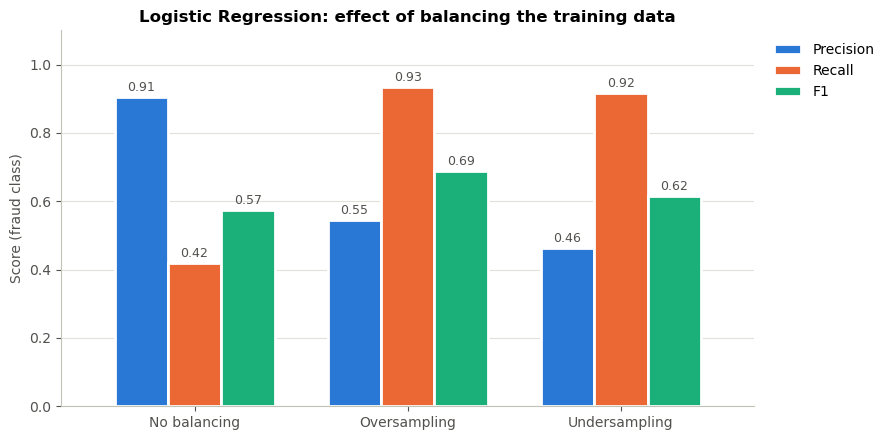

In [53]:
# Compare: Logistic Regression without balancing vs. oversampling vs. undersampling (fraud class)
balance_preds = {
    "No balancing": log_reg.predict(X_test_scaled),
    "Oversampling": pred_over,
    "Undersampling": pred_under,
}

balance_results = []
for name, model_pred in balance_preds.items():
    balance_results.append({
        "Method": name,
        "Precision": precision_score(y_test, model_pred),
        "Recall": recall_score(y_test, model_pred),
        "F1": f1_score(y_test, model_pred),
    })

balance_df = pd.DataFrame(balance_results).set_index("Method")
print(balance_df.round(4))

# Grouped bar chart (same metric colors as the other charts, legend outside the bars)
fig, ax = plt.subplots(figsize=(9, 4.5))
balance_df.plot(kind="bar", ax=ax, rot=0, width=0.75,
                color=[METRIC_COLORS[m] for m in balance_df.columns], edgecolor="white", linewidth=2)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=9, color="#52514e")
ax.set_ylim(0, 1.1)
ax.set_xlabel("")
ax.set_ylabel("Score (fraud class)")
ax.set_title("Logistic Regression: effect of balancing the training data")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("balancing_logreg.png", dpi=150)   # saved for the slides
plt.show()

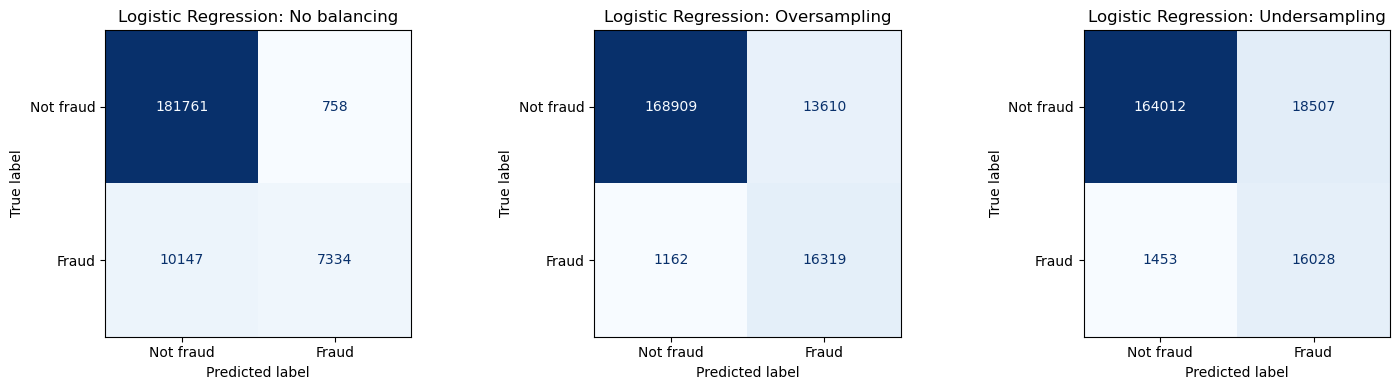

In [46]:
# Confusion matrices side by side: how many fraud cases are caught / missed with each method
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model_pred) in zip(axes, balance_preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model_pred,
                                            display_labels=["Not fraud", "Fraud"],
                                            values_format="d",
                                            cmap="Blues",
                                            colorbar=False,
                                            ax=ax)
    ax.set_title(f"Logistic Regression: {name}")

plt.tight_layout()
plt.savefig("balancing_confusion_matrices.png", dpi=150)   # saved for the slides
plt.show()

**Result:**

| Logistic Regression | Fraud caught | Fraud missed | False alarms | Precision | Recall | F1 |
|---|---|---|---|---|---|---|
| No balancing | 7,334 | 10,147 | 758 | 0.906 | 0.420 | 0.574 |
| Oversampling | 16,319 | 1,162 | 13,610 | 0.545 | 0.934 | 0.688 |
| Undersampling | 16,028 | 1,453 | 18,507 | 0.464 | 0.917 | 0.616 |

- **Balancing works as expected:** recall rises from 42% to 93%, so the model now catches most fraud cases. The price is many more false alarms (precision falls from 0.91 to 0.55).
- **Oversampling is better than undersampling** (F1 0.69 vs. 0.62), because undersampling throws away about 90% of the normal training rows.
- **Even balanced, Logistic Regression stays far behind the tree models.** Balancing was only applied to Logistic Regression: the tree models already catch almost all fraud without it, so it could not improve them.

# Part 6: Conclusion

## Summary

**Goal:** predict whether a card transaction is fraud, on 1,000,000 transactions with 7 features and 8.74% fraud.

**Best model: Decision Tree** (7 original features, MinMaxScaler, `max_depth=10`)
- Caught **all 17,481 fraud cases** in the test set and raised only **2 false alarms** out of 182,519 normal transactions.
- Random Forest and Bagging perform equally well, but the single tree is faster and easier to explain.

| Model | Precision | Recall | F1 |
|---|---|---|---|
| KNN, no scaling (baseline) | 0.901 | 0.930 | 0.915 |
| KNN with MinMaxScaler (B2) | 0.997 | 0.993 | 0.995 |
| Logistic Regression | 0.906 | 0.420 | 0.574 |
| Logistic Regression + oversampling | 0.545 | 0.934 | 0.688 |
| Decision Tree | 1.000 | 1.000 | 1.000 |
| Bagging | 1.000 | 1.000 | 1.000 |
| Random Forest | 1.000 | 1.000 | 1.000 |
| Gradient Boosting | 1.000 | 0.997 | 0.999 |
| AdaBoost | 0.998 | 0.999 | 0.999 |

(Scores for the fraud class on the test set, rounded to 3 decimals.)

## Key takeaways

1. **Accuracy is misleading here:** a model that always says "not fraud" already reaches 91.26% accuracy. Precision, recall and F1 for the fraud class were used instead.
2. **Fraud follows clear patterns:** purchases far above the customer's usual amount, online orders, no PIN and transactions far from home.
3. **Scaling was essential for KNN** (recall from 93% to 99%), while tree models do not need it.
4. **Tree-based models perform best,** because the fraud labels follow combined "if ... and ... then" rules that trees learn directly.
5. **Feature importance:** the purchase-price ratio is by far the strongest signal. **6 of 7 features are enough** for the Decision Tree: `repeat_retailer` can be dropped without losing performance.
6. **Balancing the data** (oversampling / undersampling) raised Logistic Regression's recall from 42% to 93%, at the cost of many more false alarms, but it still stays far behind the tree models.

## Limitations

- The dataset is most likely **synthetic**: the fraud labels seem to follow simple rules with round thresholds (e.g. purchase ratio > 4, distance > 100, see section 20). The near-perfect scores show that the models learned these rules, **not** that they would work this well on real fraud data.
- All results come from **one train-test split**, and the model hyperparameters were **not tuned**.

## Next steps

- Check that the results are stable with **cross-validation**.
- **Tune hyperparameters** with Grid Search or Random Search (e.g. `k` for KNN, settings for Logistic Regression).
- Try **SMOTE** for Logistic Regression and compare it with random oversampling.
- Test the approach on a **real-world fraud dataset**, where performance will be lower and the precision/recall trade-off will matter much more.